# Wine Quality · EDA e agrupamento com K-Means

O objetivo é investigar se grupos de vinhos formados pelas características físico-químicas coincidem com as notas de qualidade e se a composição dos clusters está associada ao tipo de vinho.

## EDA estrutural

Os dois arquivos são empilhados, e a coluna `tipo_vinho` identifica tintos e brancos. A base combinada tem 13 colunas: 11 medidas numéricas, a nota ordinal `quality` e o tipo de vinho, que é categórico nominal.

In [1]:
import pandas as pd
from IPython.display import display

tintos = pd.read_csv("../../data/parte_comum/winequality-red.csv", sep=";")
brancos = pd.read_csv("../../data/parte_comum/winequality-white.csv", sep=";")

tintos["tipo_vinho"] = "tinto"
brancos["tipo_vinho"] = "branco"

vinhos = pd.concat([tintos, brancos], ignore_index=True)

print(f"Dimensões da base combinada: {vinhos.shape}")
display(vinhos.head())

Dimensões da base combinada: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vinho
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


In [2]:
estrutura = pd.DataFrame({
    "tipo_de_dado": vinhos.dtypes.astype(str),
    "valores_ausentes": vinhos.isna().sum(),
    "valores_distintos": vinhos.nunique(),
})

display(estrutura)

print(f"Linhas repetidas além da primeira ocorrência: {vinhos.duplicated().sum()}")

,tipo_de_dado,valores_ausentes,valores_distintos
fixed acidity,float64,0,106
volatile acidity,float64,0,187
citric acid,float64,0,89
residual sugar,float64,0,316
chlorides,float64,0,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,0,108
sulphates,float64,0,111


Linhas repetidas além da primeira ocorrência: 1177


A base combinada tem **6.497 amostras** e nenhum valor ausente. Foram encontradas **1.177 linhas repetidas além da primeira ocorrência**. Mantivemos essas linhas, pois os arquivos identificam as amostras por suas características registradas, sem um identificador que permita confirmar se linhas iguais correspondem ao mesmo vinho registrado duas vezes. A presença de linhas repetidas pode dar mais peso a certas combinações de medidas no ajuste do K-Means.

## EDA distribucional

As contagens por nota e tipo mostram o tamanho de cada grupo. O gráfico usa percentuais dentro de cada tipo para permitir a comparação entre brancos e tintos, que têm tamanhos diferentes.

In [3]:
notas_por_tipo = pd.crosstab(
    index=vinhos["quality"],
    columns=vinhos["tipo_vinho"],
    margins=True,
    margins_name="Total",
)

display(notas_por_tipo)

classes = sorted(vinhos["quality"].dropna().unique())
k_fixo = len(classes)

print(f"Notas observadas: {classes}")
print(f"k da segunda passada: {k_fixo}")

tipo_vinho,branco,tinto,Total
quality,,,
3,20,10,30
4,163,53,216
5,1457,681,2138
6,2198,638,2836
7,880,199,1079
8,175,18,193
9,5,0,5
Total,4898,1599,6497


Notas observadas: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
k da segunda passada: 7


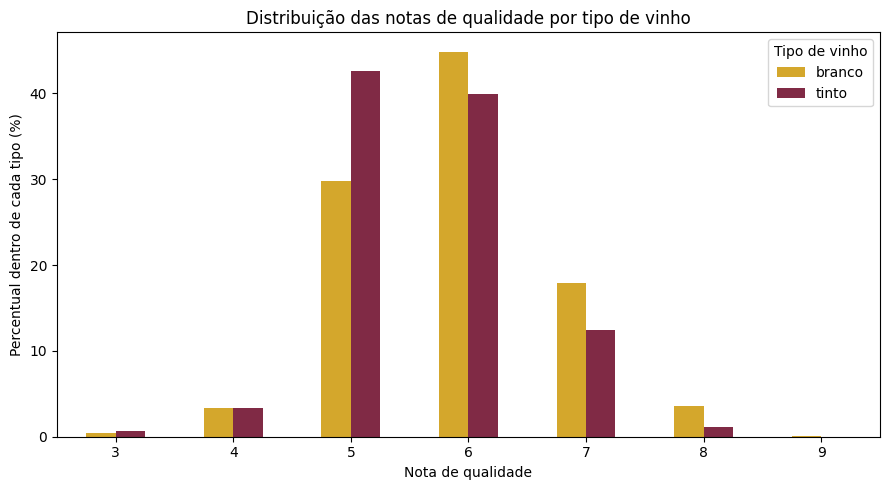

In [4]:
import matplotlib.pyplot as plt

percentual_por_tipo = pd.crosstab(
    vinhos["quality"],
    vinhos["tipo_vinho"],
    normalize="columns",
).mul(100)

ax = percentual_por_tipo.plot.bar(
    figsize=(9, 5),
    color=["#D4A72C", "#802A45"],
    rot=0,
)

ax.set_title("Distribuição das notas de qualidade por tipo de vinho")
ax.set_xlabel("Nota de qualidade")
ax.set_ylabel("Percentual dentro de cada tipo (%)")
ax.legend(title="Tipo de vinho")

plt.tight_layout()
plt.show()

As notas 5 e 6 representam 76,6% da base combinada. Entre os vinhos brancos, a nota mais frequente é 6 (44,9%). Entre os tintos, é 5 (42,6%). Essa concentração ajuda a interpretar a avaliação do K-Means: mesmo com sete clusters, a regra da classe majoritária pode atribuir a mesma nota a vários grupos e deixar notas raras sem nenhum grupo associado. Por isso, vamos analisar o recall de cada nota junto com a acurácia global.

In [5]:
medidas_fisico_quimicas = vinhos.drop(columns=["quality", "tipo_vinho"])

resumo = medidas_fisico_quimicas.describe().T.rename(
    columns={
        "count": "observações",
        "mean": "média",
        "std": "desvio padrão",
        "min": "mínimo",
        "25%": "Q1",
        "50%": "mediana",
        "75%": "Q3",
        "max": "máximo",
    }
)

display(resumo.round(3))

,observações,média,desvio padrão,mínimo,Q1,mediana,Q3,máximo
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


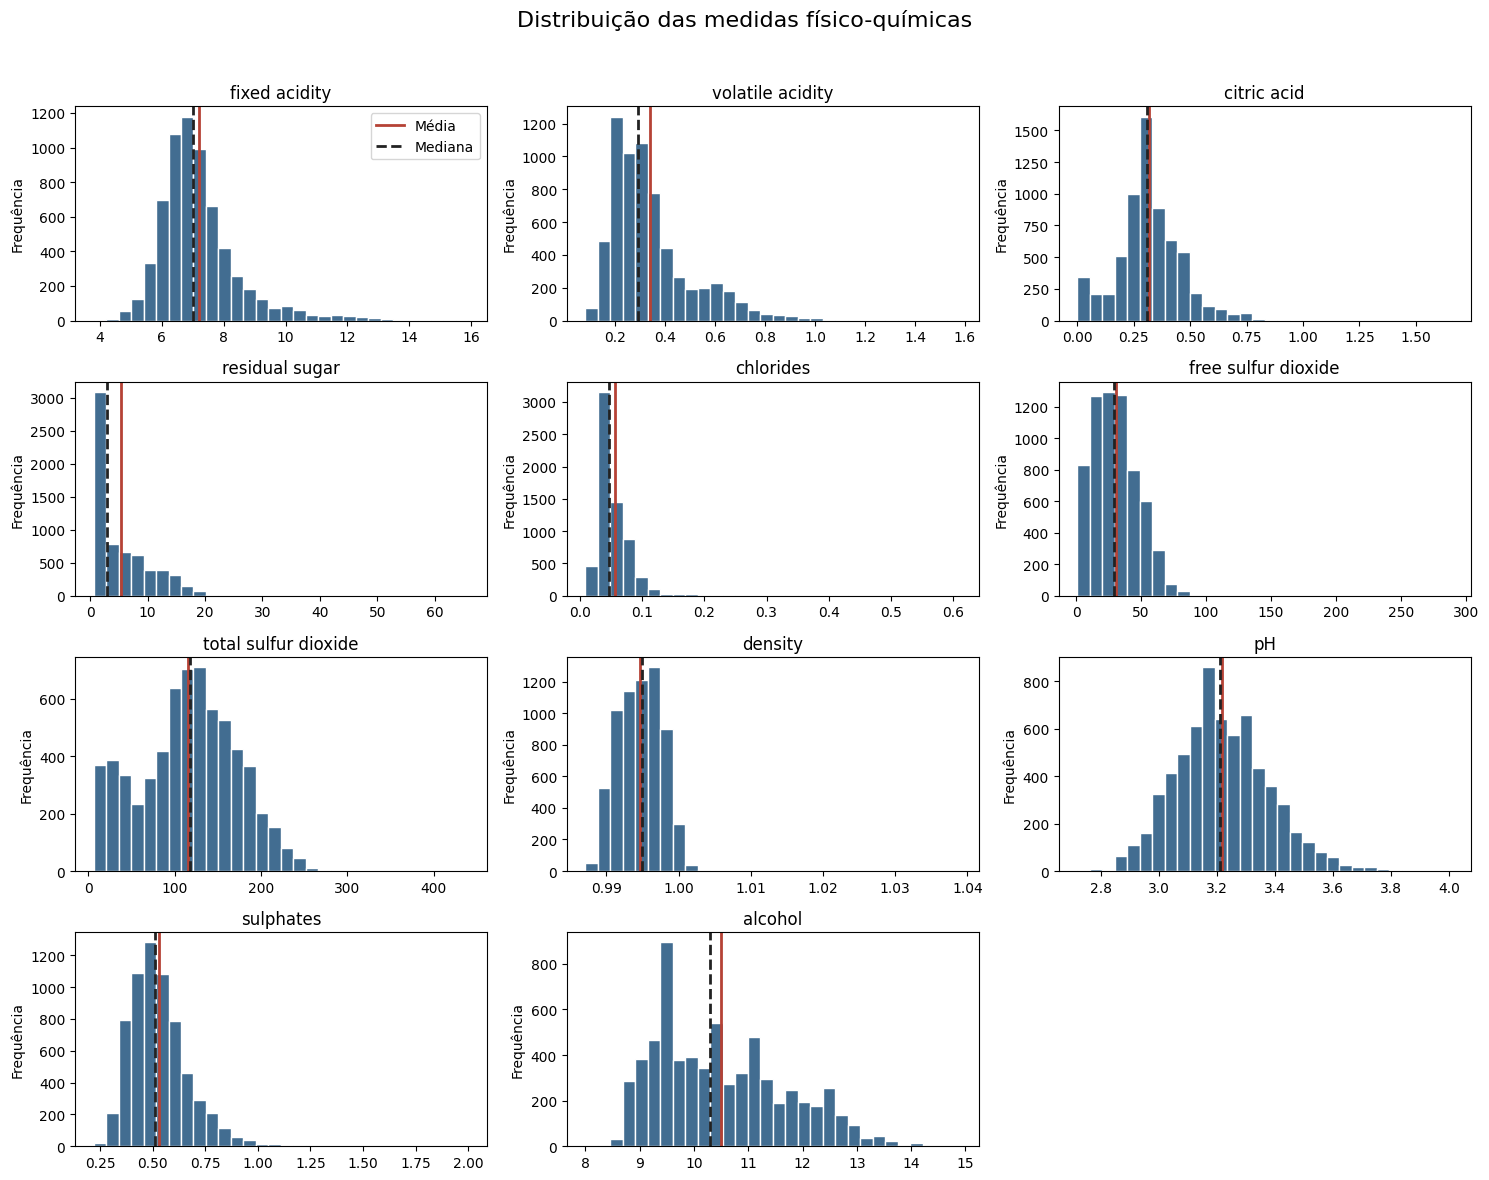

In [6]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(4, 3, figsize=(15, 12))

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    valores = medidas_fisico_quimicas[coluna]

    ax.hist(valores, bins=30, color="#426D91", edgecolor="white")
    ax.axvline(valores.mean(), color="#B54235", linewidth=2, label="Média")
    ax.axvline(
        valores.median(),
        color="#222222",
        linestyle="--",
        linewidth=2,
        label="Mediana",
    )

    ax.set_title(coluna)
    ax.set_ylabel("Frequência")

eixos.flat[-1].set_visible(False)
eixos.flat[0].legend()

fig.suptitle("Distribuição das medidas físico-químicas", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

O açúcar residual teve mediana de **3,00**, média de **5,44** e máximo de **65,8**. O contraste entre a concentração de valores baixos e a cauda de valores altos no histograma indica assimetria à direita.

## EDA relacional

A matriz de Spearman resume as associações entre pares de medidas. Os boxplots comparam as distribuições de cada medida por nota e por tipo de vinho.

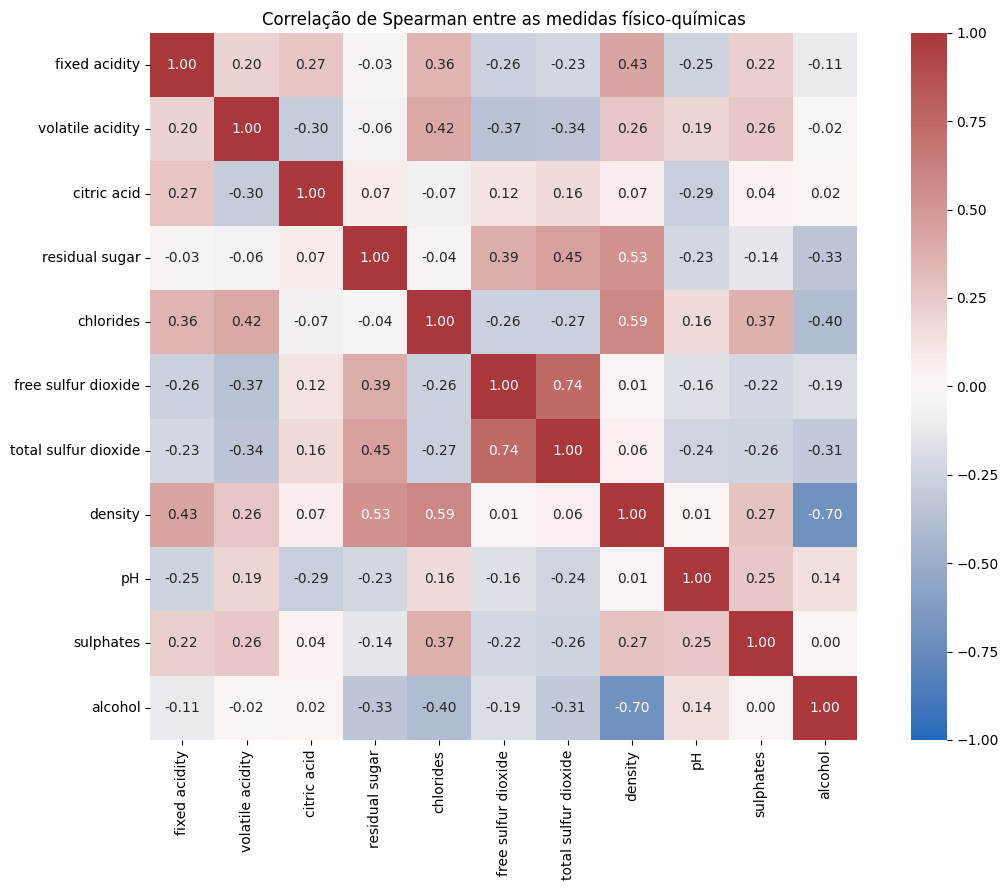

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

correlacoes = medidas_fisico_quimicas.corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Correlação de Spearman entre as medidas físico-químicas")
plt.tight_layout()
plt.show()

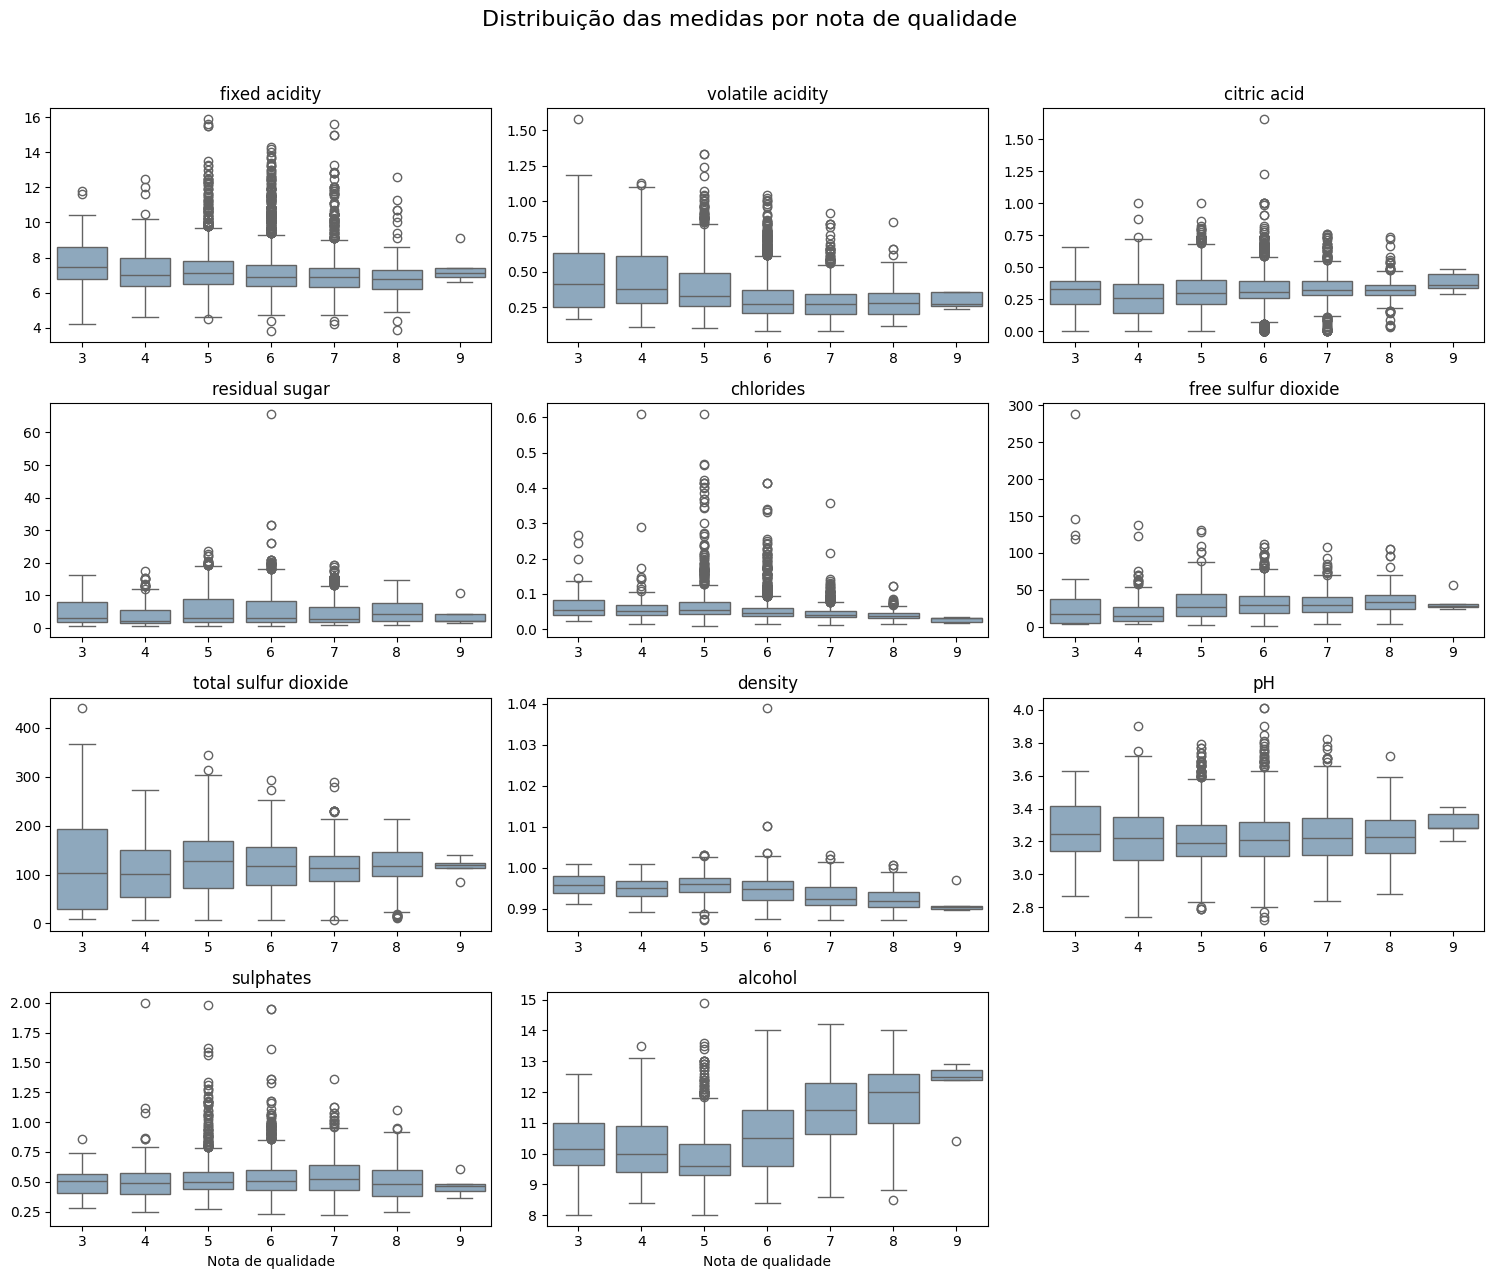

In [8]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 13), sharex=True)

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    sns.boxplot(
        data=vinhos,
        x="quality",
        y=coluna,
        order=classes,
        color="#86A9C5",
        ax=ax,
    )
    ax.set_title(coluna)
    ax.set_xlabel("Nota de qualidade")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelbottom=True)

eixos.flat[-1].set_visible(False)
fig.suptitle("Distribuição das medidas por nota de qualidade", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

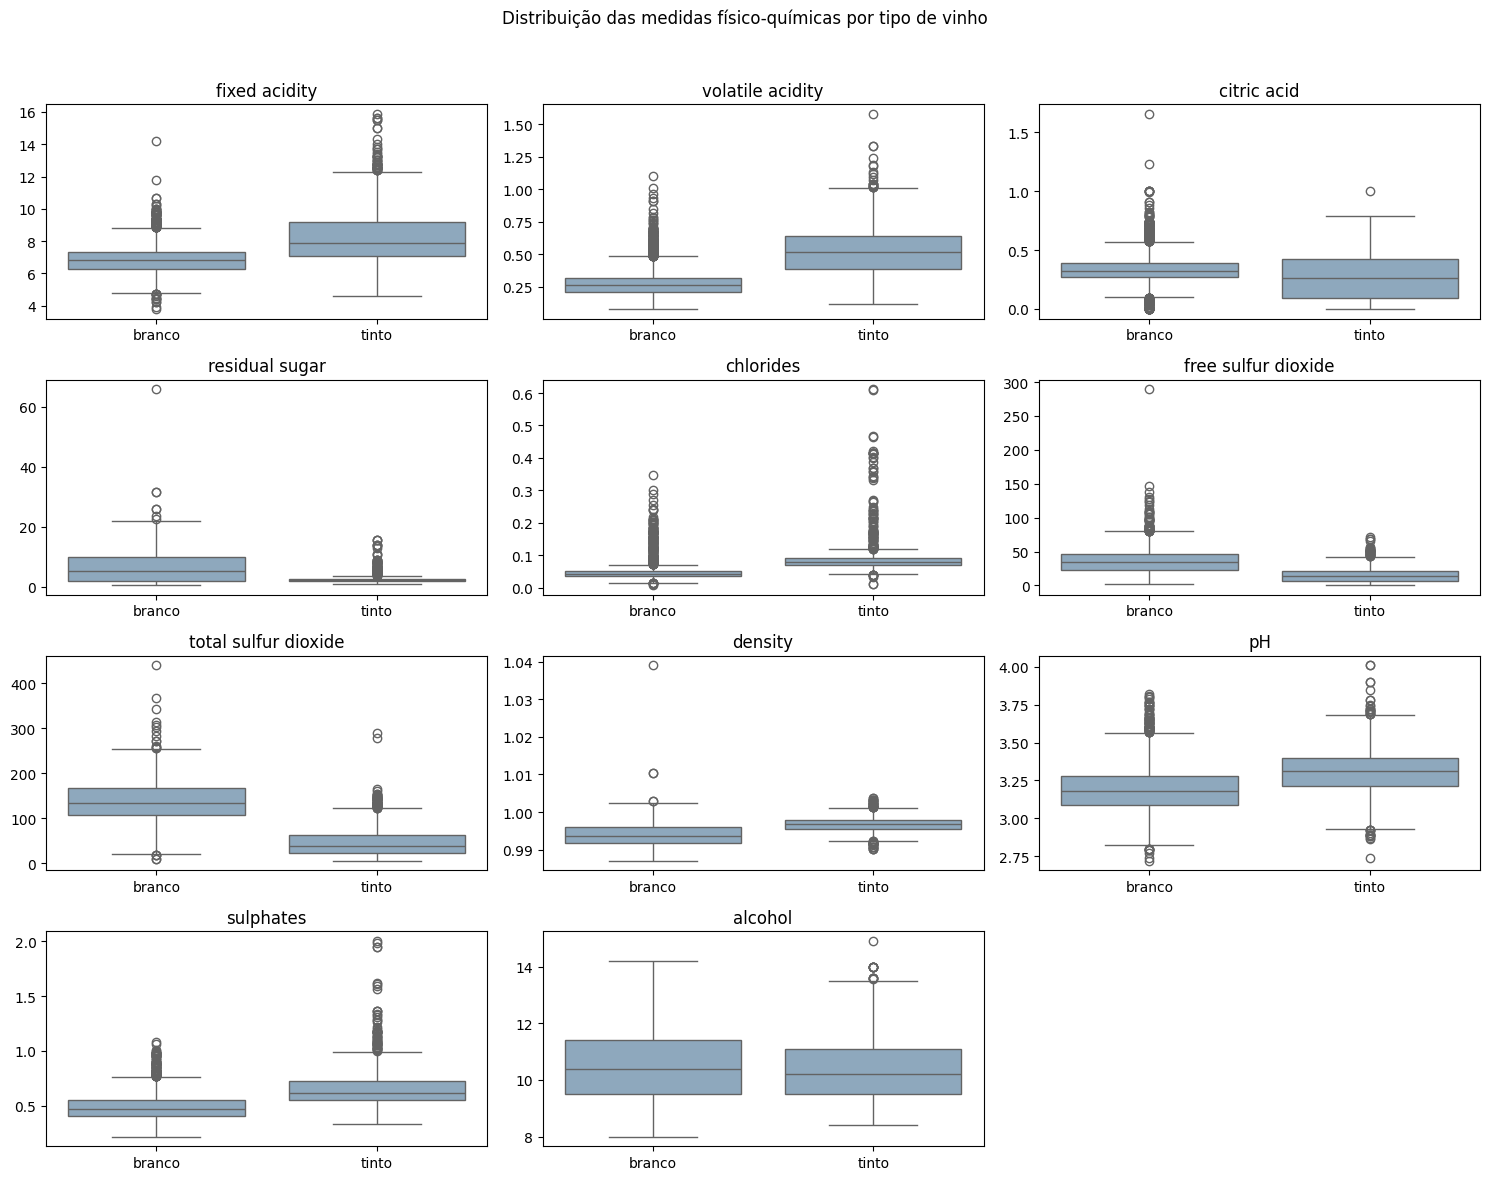

In [9]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 12))

for coluna, ax in zip(medidas_fisico_quimicas.columns, eixos.flat):
    sns.boxplot(
        data=vinhos,
        x="tipo_vinho",
        y=coluna,
        order=["branco", "tinto"],
        color="#86A9C5",
        ax=ax,
    )
    ax.set_title(coluna)
    ax.set_xlabel("")
    ax.set_ylabel("")

eixos.flat[-1].set_visible(False)
fig.suptitle("Distribuição das medidas físico-químicas por tipo de vinho")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

O dióxido de enxofre livre e o total apresentaram correlação de Spearman de **0,74**. Densidade e teor alcoólico apresentaram correlação de **−0,70**. Os coeficientes descrevem associações na base combinada.

A mediana do teor alcoólico sobe da nota 5 para a 6 e segue aumentando até a 8, com sobreposição entre as distribuições. Em açúcar residual, as notas 5 e 6 têm medianas próximas e caixas bastante sobrepostas. Por tipo, o dióxido de enxofre total apresenta uma separação visual clara entre as caixas dos brancos e dos tintos. Essa diferença ajuda a formular a hipótese de que os clusters possam refletir o tipo de vinho.

## Outliers

Usamos os limites `Q1 − 1,5 × IQR` e `Q3 + 1,5 × IQR`, com `IQR = Q3 − Q1`, calculados por medida na base combinada.

In [10]:
q1 = medidas_fisico_quimicas.quantile(0.25)
q3 = medidas_fisico_quimicas.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

fora_dos_limites = (
    medidas_fisico_quimicas.lt(limite_inferior)
    | medidas_fisico_quimicas.gt(limite_superior)
)

resumo_outliers = pd.DataFrame({
    "limite inferior": limite_inferior,
    "limite superior": limite_superior,
    "valores sinalizados": fora_dos_limites.sum(),
    "% da base": fora_dos_limites.mean().mul(100),
}).sort_values("valores sinalizados", ascending=False)

display(resumo_outliers.round(4))

linhas_sinalizadas = fora_dos_limites.any(axis=1)
print(f"Amostras com pelo menos um valor sinalizado: {linhas_sinalizadas.sum()}")
print(f"Percentual da base: {linhas_sinalizadas.mean():.1%}")

# Examinar se os maiores valores de açúcar e densidade aparecem na mesma amostra.
colunas_inspecao = ["tipo_vinho", "quality", "residual sugar", "density"]
indices_extremos = [
    vinhos["residual sugar"].idxmax(),
    vinhos["density"].idxmax(),
]

display(vinhos.loc[list(dict.fromkeys(indices_extremos)), colunas_inspecao])

,limite inferior,limite superior,valores sinalizados,% da base
citric acid,0.0400,0.6000,509,7.8344
volatile acidity,-0.0250,0.6550,377,5.8027
fixed acidity,4.4500,9.6500,357,5.4948
chlorides,-0.0025,0.1055,286,4.4020
sulphates,0.1750,0.8550,191,2.9398
residual sugar,-7.6500,17.5500,118,1.8162
pH,2.7950,3.6350,73,1.1236
free sulfur dioxide,-19.0000,77.0000,62,0.9543
total sulfur dioxide,-41.5000,274.5000,10,0.1539
density,0.9854,1.0040,3,0.0462


Amostras com pelo menos um valor sinalizado: 1473
Percentual da base: 22.7%


,tipo_vinho,quality,residual sugar,density
4380,branco,6,65.8,1.03898


In [11]:
diagnostico_outliers = (
    vinhos[["tipo_vinho"]]
    .assign(sinalizada=fora_dos_limites.any(axis=1))
    .groupby("tipo_vinho")["sinalizada"]
    .agg(amostras="size", sinalizadas="sum")
)

diagnostico_outliers.loc["Total"] = diagnostico_outliers.sum()

diagnostico_outliers["% sinalizadas"] = (
    diagnostico_outliers["sinalizadas"]
    .div(diagnostico_outliers["amostras"])
    .mul(100)
    .round(2)
)

display(diagnostico_outliers)

,amostras,sinalizadas,% sinalizadas
tipo_vinho,,,
branco,4898,562,11.47
tinto,1599,911,56.97
Total,6497,1473,22.67


O IQR sinalizou **1.473 amostras (22,67%)** com pelo menos uma medida fora dos limites. A proporção foi de **56,97%** entre tintos e **11,47%** entre brancos. Os máximos de açúcar residual (**65,8**) e densidade (**1,03898**) ocorreram na mesma amostra, um vinho branco de nota 6. Mantivemos todas as amostras na análise principal porque o critério estatístico, sozinho, é insuficiente para estabelecer erro de medição, e a exclusão automática alteraria a composição por tipo. Valores extremos podem influenciar os centroides.

## Padronização

O K-Means usa distâncias euclidianas. Antes da padronização, medidas com maior escala, como o dióxido de enxofre total, podem ter mais peso na distância que medidas como o pH. O `StandardScaler` centra as 11 medidas e expressa as diferenças em unidades de desvio padrão. A nota e o tipo de vinho são usados para avaliar e interpretar os grupos após o ajuste.

In [12]:
from sklearn.preprocessing import StandardScaler

padronizador = StandardScaler()

X_padronizado = pd.DataFrame(
    padronizador.fit_transform(medidas_fisico_quimicas),
    columns=medidas_fisico_quimicas.columns,
    index=vinhos.index,
)

print(f"Dimensões dos dados para o K-Means: {X_padronizado.shape}")

display(
    pd.DataFrame({
        "média": X_padronizado.mean(),
        "desvio padrão": X_padronizado.std(ddof=0),
    }).round(4)
)

Dimensões dos dados para o K-Means: (6497, 11)


,média,desvio padrão
fixed acidity,-0.0,1.0
volatile acidity,0.0,1.0
citric acid,0.0,1.0
residual sugar,0.0,1.0
chlorides,0.0,1.0
free sulfur dioxide,-0.0,1.0
total sulfur dioxide,-0.0,1.0
density,-0.0,1.0
pH,0.0,1.0
sulphates,-0.0,1.0


## K-Means e Método do Cotovelo

Ajustamos modelos para `k` de 2 a 10 sobre os mesmos dados padronizados. A inércia é a soma das distâncias quadráticas de cada amostra ao centro do seu grupo. A curva mostra quanto essa soma diminui à medida que acrescentamos grupos.

,inércia
k,
2,56143.9
3,45577.0
4,40721.0
5,38069.2
6,35831.2
7,34054.1
8,32898.2
9,31667.1
10,30589.6


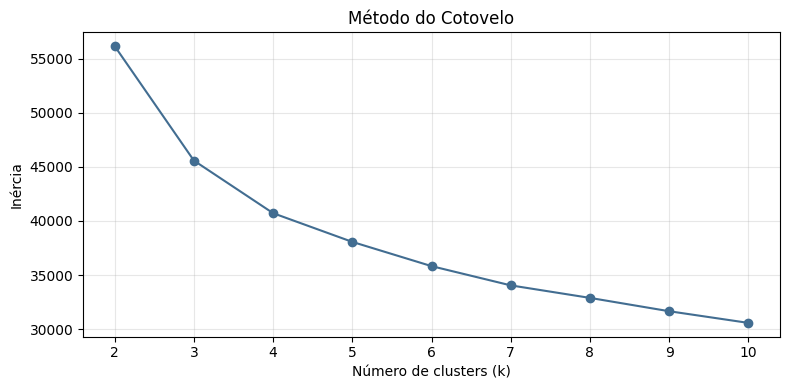

In [13]:
from sklearn.cluster import KMeans

modelos_kmeans = {}
inercia_por_k = {}

for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
    modelo.fit(X_padronizado)

    modelos_kmeans[k] = modelo
    inercia_por_k[k] = modelo.inertia_

cotovelo = pd.Series(inercia_por_k, name="inércia").rename_axis("k")
display(cotovelo.to_frame().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cotovelo.index, cotovelo.values, marker="o", color="#426D91")
ax.set_title("Método do Cotovelo")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia")
ax.set_xticks(cotovelo.index)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Escolhemos **`k = 4`** na primeira passada. A inércia caiu **4.856,0** de três para quatro grupos e **2.651,8** de quatro para cinco. A desaceleração é gradual, o que torna a escolha aproximada. Na segunda passada, usamos **`k = 7`**, o número de notas distintas observadas.

Mostramos as duas passadas nos mesmos eixos do PCA. Eles explicam **50,2%** da variância. A projeção serve para visualizar os resultados, e os grupos foram ajustados nas 11 dimensões padronizadas.

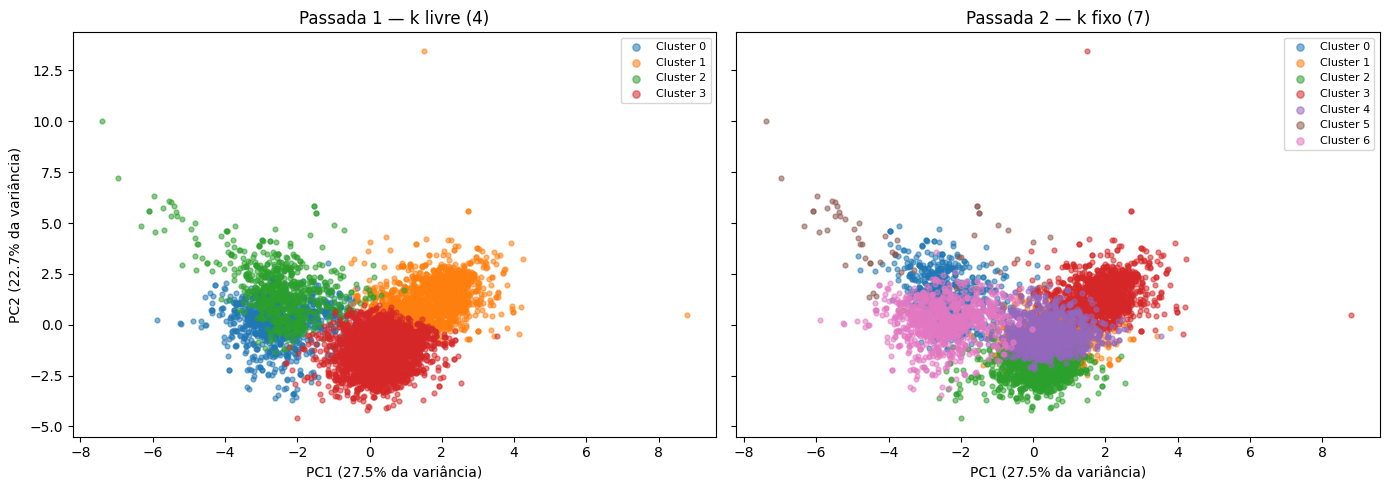

Variância explicada pelos dois eixos: 50.2%


In [14]:
from sklearn.decomposition import PCA

k_livre = 4

modelo_livre = modelos_kmeans[k_livre]
modelo_fixo = modelos_kmeans[k_fixo]

pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_padronizado)
variancia = pca.explained_variance_ratio_ * 100

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

passadas = [
    (modelo_livre, f"Passada 1 — k livre ({k_livre})"),
    (modelo_fixo, f"Passada 2 — k fixo ({k_fixo})"),
]

for ax, (modelo, titulo) in zip(eixos, passadas):
    for cluster in range(modelo.n_clusters):
        pertence_ao_cluster = modelo.labels_ == cluster
        ax.scatter(
            coordenadas[pertence_ao_cluster, 0],
            coordenadas[pertence_ao_cluster, 1],
            s=12,
            alpha=0.55,
            label=f"Cluster {cluster}",
        )

    ax.set_title(titulo)
    ax.set_xlabel(f"PC1 ({variancia[0]:.1f}% da variância)")
    ax.legend(fontsize=8, markerscale=1.5)

eixos[0].set_ylabel(f"PC2 ({variancia[1]:.1f}% da variância)")
plt.tight_layout()
plt.show()

print(f"Variância explicada pelos dois eixos: {variancia.sum():.1f}%")

## Avaliação dos agrupamentos

Cada cluster recebe sua nota real mais frequente. A tabela de contingência cruza **nota real × cluster** e tem dimensões **7 × 4** ou **7 × 7**. Após o mapeamento, as matrizes de confusão são **7 × 7** porque cruzam **nota real × nota atribuída**. Na ausência de atribuições a uma nota, a precisão é indefinida (`NaN`). A silhueta é calculada nas 11 dimensões padronizadas.

Para cada nota, a acurácia um-contra-o-resto é (verdadeiros positivos + verdadeiros negativos) / total de amostras. A acurácia global compara diretamente a nota atribuída com a nota real.


Passada 1 — k livre (4)
Contagem de notas reais por cluster


cluster,0,1,2,3
quality,,,,
3,7,10,5,8
4,71,44,20,81
5,503,797,229,609
6,366,833,285,1352
7,53,157,136,733
8,6,31,12,144
9,0,1,0,4


Tamanho, nota majoritária e tipo de vinho por cluster


tipo_vinho,amostras,nota majoritária,branco (%),tinto (%)
cluster,,,,
0,1006,5,8.8,91.2
1,1873,6,99.8,0.2
2,687,6,7.1,92.9
3,2931,6,98.6,1.4


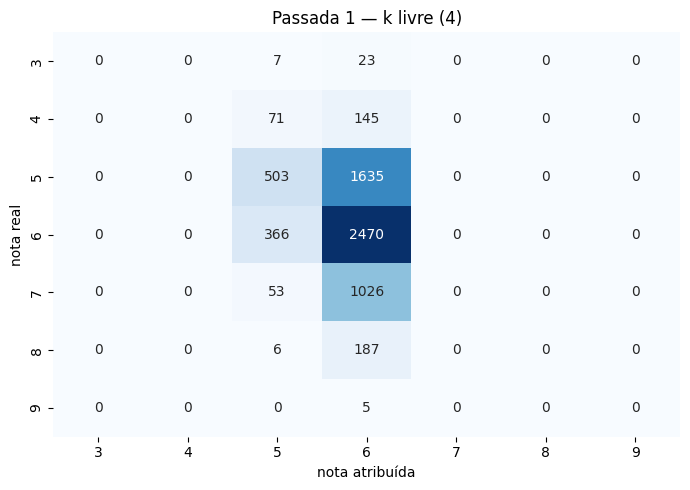

Métricas por nota


,amostras reais,amostras atribuídas,acurácia (1 vs. demais),precisão,recall
3,30,0,0.995,NaN,0.000
4,216,0,0.967,NaN,0.000
5,2138,1006,0.671,0.50,0.235
6,2836,5491,0.479,0.45,0.871
7,1079,0,0.834,NaN,0.000
8,193,0,0.970,NaN,0.000
9,5,0,0.999,NaN,0.000



Passada 2 — k fixo (7)
Contagem de notas reais por cluster


cluster,0,1,2,3,4,5,6
quality,,,,,,,
3,4,2,4,7,5,2,6
4,14,28,20,24,63,2,65
5,182,302,78,650,411,30,485
6,259,505,527,646,536,19,344
7,139,175,454,122,144,2,43
8,12,30,96,21,30,0,4
9,0,0,4,1,0,0,0


Tamanho, nota majoritária e tipo de vinho por cluster


tipo_vinho,amostras,nota majoritária,branco (%),tinto (%)
cluster,,,,
0,610,6,2.3,97.7
1,1042,6,98.1,1.9
2,1183,6,97.3,2.7
3,1471,5,99.9,0.1
4,1189,6,99.3,0.7
5,55,5,18.2,81.8
6,947,5,5.4,94.6


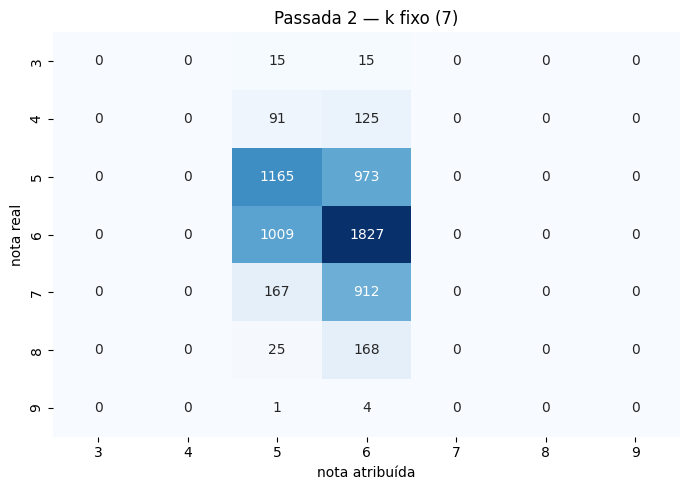

Métricas por nota


,amostras reais,amostras atribuídas,acurácia (1 vs. demais),precisão,recall
3,30,0,0.995,NaN,0.000
4,216,0,0.967,NaN,0.000
5,2138,2473,0.649,0.471,0.545
6,2836,4024,0.507,0.454,0.644
7,1079,0,0.834,NaN,0.000
8,193,0,0.970,NaN,0.000
9,5,0,0.999,NaN,0.000


,acurácia,silhueta
k,,
4,0.458,0.248
7,0.461,0.180


Acurácia de referência ao atribuir sempre a nota 6: 43.7%


In [15]:
from sklearn.metrics import confusion_matrix, silhouette_score

notas_reais = vinhos["quality"]
resultados = []

for modelo, titulo in passadas:
    print(f"\n{titulo}")

    clusters = pd.Series(modelo.labels_, index=vinhos.index, name="cluster")

    # Composição antes do mapeamento: notas reais × clusters.
    notas_por_cluster = pd.crosstab(notas_reais, clusters).reindex(
        index=classes, fill_value=0
    )
    print("Contagem de notas reais por cluster")
    display(notas_por_cluster)

    # Em caso de empate, idxmax escolhe a primeira nota na ordem crescente.
    nota_majoritaria = notas_por_cluster.idxmax(axis=0)
    notas_atribuidas = clusters.map(nota_majoritaria)

    tipo_por_cluster = pd.crosstab(
        clusters, vinhos["tipo_vinho"], normalize="index"
    ).mul(100)

    composicao = tipo_por_cluster.add_suffix(" (%)").round(1)
    composicao.insert(0, "amostras", notas_por_cluster.sum(axis=0))
    composicao.insert(1, "nota majoritária", nota_majoritaria)

    print("Tamanho, nota majoritária e tipo de vinho por cluster")
    display(composicao)

    # Matriz após o mapeamento: notas reais × notas atribuídas.
    matriz = pd.DataFrame(
        confusion_matrix(notas_reais, notas_atribuidas, labels=classes),
        index=pd.Index(classes, name="nota real"),
        columns=pd.Index(classes, name="nota atribuída"),
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

    acertos = pd.Series(matriz.to_numpy().diagonal(), index=classes)
    total_atribuidas = matriz.sum(axis=0)
    total_reais = matriz.sum(axis=1)

    # [IA] Codex – apoio no cálculo e na verificação da acurácia de cada nota contra as demais.
    total = int(matriz.to_numpy().sum())
    verdadeiros_negativos = total - total_reais - total_atribuidas + acertos
    acuracia_por_nota = (acertos + verdadeiros_negativos) / total
    for nota in classes:
        concordancia_binaria = (notas_reais.eq(nota) == notas_atribuidas.eq(nota)).mean()
        assert abs(acuracia_por_nota.loc[nota] - concordancia_binaria) < 1e-12

    metricas = pd.DataFrame({
        "amostras reais": total_reais,
        "amostras atribuídas": total_atribuidas,
        "acurácia (1 vs. demais)": acuracia_por_nota,
        "precisão": acertos.div(total_atribuidas.where(total_atribuidas.gt(0))),
        "recall": acertos.div(total_reais),
    })

    print("Métricas por nota")
    display(metricas.round(3))

    resultados.append({
        "k": modelo.n_clusters,
        "acurácia": acertos.sum() / len(vinhos),
        "silhueta": silhouette_score(X_padronizado, clusters),
    })

comparacao = pd.DataFrame(resultados).set_index("k")
display(comparacao.round(3))

referencia = notas_reais.value_counts(normalize=True).max()
print(f"Acurácia de referência ao atribuir sempre a nota 6: {referencia:.1%}")

## Discussão crítica e conclusão

| Indicador | k = 4 | k = 7 |
|---|---:|---:|
| Silhueta | 0,248 | 0,180 |
| Acurácia após o mapeamento | 45,8% | 46,1% |
| Precisão da nota 5 | 50,0% | 47,1% |
| Recall da nota 5 | 23,5% | 54,5% |
| Precisão da nota 6 | 45,0% | 45,4% |
| Recall da nota 6 | 87,1% | 64,4% |

**Coerência dos grupos.** Entre as duas passadas, quatro clusters apresentaram a maior silhueta, sinal de melhor compactação e separação relativas nas medidas usadas. Com sete clusters, houve apenas 19 coincidências adicionais entre notas reais e atribuídas. Ambas as acurácias ficaram próximas dos 43,7% obtidos ao atribuir sempre a nota 6. A acurácia mede concordância na base analisada, pois os rótulos reais são usados após o ajuste para mapear os clusters.

**Tipo de vinho.** Com quatro clusters, dois tinham mais de 91% de tintos e os outros dois tinham mais de 98% de brancos. Com sete clusters, o predomínio de um tipo por grupo também foi observado. Isso é compatível com as diferenças entre tintos e brancos encontradas na EDA.

**Granularidade das notas.** As duas passadas atribuíram apenas as notas 5 e 6. As notas 3, 4, 7, 8 e 9 tiveram recall zero porque nenhuma foi a mais frequente dentro de um cluster. Com sete clusters, um deles reuniu **650 vinhos de nota 5 e 646 de nota 6**, recebendo a nota 5 por uma diferença de quatro amostras. Esse exemplo, junto com a sobreposição dos boxplots, indica que as notas 5 e 6 são difíceis de separar com o método e as medidas usados. Uma proposta de fusão precisaria de evidências adicionais, como verificar se a sobreposição persiste dentro de cada tipo de vinho.